# Cross Validation, Model Selection & Regularisation

Signification des émoticones :
- 🌞 : documentations importantes
- 👀 : documentations intéressantes à connaître
- 🌚 : en complément
- (vide) : à vous de voir

In this notebook we will introduce the concepts below, and how they can be implemented in `scikit-learn`.
* Cross validation - a method for estimating the test error rate when test data is not available
* Model selection - how we use cross validation to select which model (from a selection) we should use for a particular data set
* Regularisation - an adaptation of linear regression to make it more flexible

[This video](https://www.youtube.com/watch?v=DQWI1kvmwRg) describes some of the ideas you will face in the coming notebook. The ideas we are covering here are described much more throughly in **ISLR** (see suggested sections in module overview).

🌚 https://trevorhastie.github.io/ISLR/

In [1]:
import pandas as pd
import numpy as np

## Cross validation

We have already seen the notion of splitting *test* and *training sets* in order to asses model performance. Now we will introduce the idea of *validation sets*.

Once again **ISTL** (Section 5.1) provides a very clear overview of how these techniques work:

>Resampling methods are an indispensable tool in modern statistics. They
involve repeatedly drawing samples from a training set and refitting a model
of interest on each sample in order to obtain additional information about
the fitted model. For example, in order to estimate the variability of a linear
regression fit, we can repeatedly draw different samples from the training
data, fit a linear regression to each new sample, and then examine the
extent to which the resulting fits differ. Such an approach may allow us to
obtain information that would not be available from fitting the model only
once using the original training sample.

>Resampling approaches can be computationally expensive, because they
involve fitting the same statistical method multiple times using different
subsets of the training data. However, due to recent advances in computing
power, the computational requirements of resampling methods generally
are not prohibitive. [...] cross-validation can be used to estimate the test
error associated with a given statistical learning method in order to evaluate
its performance, or to select the appropriate level of flexibility. The process
of evaluating a model’s performance is known as model assessment, whereas model
the process of selecting the proper level of flexibility for a model is known as assessment
model selection.

The diagram below illustrates this process. Here the train and validation sets are used to do model assesment and model selection (NOTE: the test set is strictly forbidden from being used in any way during this process!). Once a model is selected the test set is used to do a final assesment of performance to see if the model selected will generalise as well as predicted.

<img src="./images/testtrainvalid.png" width="450px">

There is a simple overview these ideas 👀[here](https://towardsdatascience.com/training-vs-testing-vs-validation-sets-a44bed52a0e1/), and a more thorough overview 🌚[here](https://machinelearningmastery.com/difference-test-validation-datasets/).

🌞 This video of Machine learnia also explains the concept of cross validation very well : https://www.youtube.com/watch?v=w_bLGK4Pteo&ab_channel=MachineLearnia

### K-fold cross validation

A very common method called *k-fold* is often used, which actually splits the training set multiple times. This allows us to assess the accuracy of the model over $k$ validation splits of data. The 🌚[image below](http://ethen8181.github.io/machine-learning/model_selection/model_selection.html) illustrates how this works for $k = 5$ splits.

<img src="./images/kfold.png" width="450px">

The `scikit-learn` documentation offers a simple 🌞[example](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) of implementing k-fold on some dummy data. We will examine this below. NOTE: The `scikit-learn` documentation is **FANSTASTIC(!)** and contains working examples of every function, it should always be the first place you look when you wish to implement a new function.

**Task 1:** 

* Have a look at the code below and check you understand what is going on. (Add some print statements in various places to help.)

In [10]:
import numpy as np
from sklearn.model_selection import KFold
X = np.array([['A', 'B'], ['C', 'D'], ['E', 'F'], ['G', 'H']])
y = np.array([1, 2, 3, 4])
kf = KFold(n_splits=3) # here we choose the number of folds (or splits) we will make
kf.get_n_splits(X)

for train_index, valid_index in kf.split(X): # kf.split(X) is an iterable which gives us the indices of the data in each fold
    X_train, X_valid = X[train_index], X[valid_index]
    y_train, y_valid = y[train_index], y[valid_index]
    print( X_train, X_valid)
    print()
    print(y_train, y_valid)
    print('=' * 80)

[['E' 'F']
 ['G' 'H']] [['A' 'B']
 ['C' 'D']]

[3 4] [1 2]
[['A' 'B']
 ['C' 'D']
 ['G' 'H']] [['E' 'F']]

[1 2 4] [3]
[['A' 'B']
 ['C' 'D']
 ['E' 'F']] [['G' 'H']]

[1 2 3] [4]


We can apply this to any data set to perform operations as it gives us the dataframe/numpy array indicies in each loop to select the appropriate data for each fold. For example we can apply this to the auto data set. This contains rows which correspond to individual cars and their attributes.

In [11]:
auto = pd.read_csv('./Data/Auto.csv')
auto = auto[auto.horsepower != '?']
auto['horsepower'] = auto.horsepower.astype(int)
auto.reset_index(inplace=True, drop=True)
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [12]:
mpg = auto.pop('mpg') # mpg will be our target and so we remove this into a seperate array

Say we are trying to predict 'mpg' from our other automobile data features. We can use KFold to iterate over the number of splits we choose.

**Task 2:**
* try adding print statements for the size of the dataframes in each split
* try increasing the number of splits and re-run your code
* use the code below to print a car name contained in the train and validation data set, for each split



In [13]:
kf = KFold(n_splits=5) # here we choose the number of folds (or splits) we will make
kf.get_n_splits(auto) # auto is the data

split_counter = 1
for train_index, valid_index in kf.split(auto): # kf.split(X) is an iterable which gives us the indices of the data in each fold
    print('-'*60)
    print('This is split no: {}'.format(split_counter))
    split_counter += 1 
    X_train, X_valid = auto.iloc[train_index], auto.iloc[valid_index] # must use .iloc because its a dataframe this time
    y_train, y_valid = mpg[train_index], mpg[valid_index]
    
    # your code here
    print('Train car name here')
    print( X_train['name'])
    print('Validation car name here')
    print( X_valid['name'])
    

------------------------------------------------------------
This is split no: 1
Train car name here
79                 ford pinto (sw)
80                 datsun 510 (sw)
81     toyouta corona mark ii (sw)
82                 dodge colt (sw)
83        toyota corolla 1600 (sw)
                  ...             
387                ford mustang gl
388                      vw pickup
389                  dodge rampage
390                    ford ranger
391                     chevy s-10
Name: name, Length: 313, dtype: object
Validation car name here
0          chevrolet chevelle malibu
1                  buick skylark 320
2                 plymouth satellite
3                      amc rebel sst
4                        ford torino
                   ...              
74    plymouth satellite custom (sw)
75                   volvo 145e (sw)
76               volkswagen 411 (sw)
77                  peugeot 504 (sw)
78                   renault 12 (sw)
Name: name, Length: 79, dtype: object
-----

In [15]:
#### Your solution here
kf = KFold(n_splits=7) # here we choose the number of folds (or splits) we will make
kf.get_n_splits(auto) # auto is the dataframe

split_counter = 1
for train_index, valid_index in kf.split(auto): # kf.split(auto) is an iterable which gives us the indices of the data in each fold
    print('-'*60)
    print('This is split no: {}'.format(split_counter))
    split_counter += 1 
    X_train, X_valid = auto.iloc[train_index], auto.iloc[valid_index] # must use .iloc because its a dataframe this time
    y_train, y_valid = mpg[train_index], mpg[valid_index]
    
    # your code here
    print('Train car name here')
    print( X_train['name'],y_train)
    print()
    print('Validation car name here')
    print( X_valid['name'], y_valid)
    print('=' * 80)



------------------------------------------------------------
This is split no: 1
Train car name here
56     toyota corona hardtop
57        dodge colt hardtop
58         volkswagen type 3
59            chevrolet vega
60       ford pinto runabout
               ...          
387          ford mustang gl
388                vw pickup
389            dodge rampage
390              ford ranger
391               chevy s-10
Name: name, Length: 336, dtype: object 56     24.0
57     25.0
58     23.0
59     20.0
60     21.0
       ... 
387    27.0
388    44.0
389    32.0
390    28.0
391    31.0
Name: mpg, Length: 336, dtype: float64

Validation car name here
0        chevrolet chevelle malibu
1                buick skylark 320
2               plymouth satellite
3                    amc rebel sst
4                      ford torino
5                 ford galaxie 500
6                 chevrolet impala
7                plymouth fury iii
8                 pontiac catalina
9               amc ambassado

In [16]:
auto = auto.drop('name', axis=1, errors='ignore') # we do not need the car names so remove for now.

We can use the same loop to fit and evaluate our linear regression model on each train/validation split:

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


split_counter = 1
mse_scores = [] # create empty list to append mse scores for each split
kf = KFold(n_splits=5)
kf.get_n_splits(auto)

for train_index, valid_index in kf.split(auto): # kf.split(X) is an iterable which gives us the indices of the data in each fold
    print('-'*60)
    print('This is split no: {}'.format(split_counter))
    print('Model results')
    split_counter += 1 
    X_train, X_valid = auto.iloc[train_index], auto.iloc[valid_index] # must use .iloc because its a dataframe this time
    y_train, y_valid = mpg[train_index], mpg[valid_index]
    
    
    #### fit polynomial to train data in this split
    lin_reg = LinearRegression()
    lin_reg.fit(X_train, y_train) # trying to predict y from x
    
    #### eval & print MSE training results in this split
    mpg_train_pred = lin_reg.predict(X_train)
    mse_train = mean_squared_error(y_train, mpg_train_pred)
    print('training MSE: {0}'.format(mse_train))
    
    #### do the same for validation split
    mpg_valid_pred = lin_reg.predict(X_valid)
    mse_valid = mean_squared_error(y_valid, mpg_valid_pred)
    print('validation MSE: {0}'.format(mse_valid))
    
    mse_scores.append(mse_valid) # assign validation MSE score to list

------------------------------------------------------------
This is split no: 1
Model results
training MSE: 11.284070590566007
validation MSE: 14.974307651304228
------------------------------------------------------------
This is split no: 2
Model results
training MSE: 11.155158050598772
validation MSE: 10.905952427081171
------------------------------------------------------------
This is split no: 3
Model results
training MSE: 12.160105136871518
validation MSE: 5.991708610108182
------------------------------------------------------------
This is split no: 4
Model results
training MSE: 9.92167414540569
validation MSE: 15.587544657621592
------------------------------------------------------------
This is split no: 5
Model results
training MSE: 7.977511689294956
validation MSE: 27.844743081984223


When using k-fold cross validation we can analyse the validation MSE result for each split to assess the overall performance.

In [60]:
mse_scores  = np.array(mse_scores)
print('VALIDATION SET MSE SCORES')
print('mean MSE:', mse_scores.mean())
print('std MSE:', mse_scores.std())

VALIDATION SET MSE SCORES
mean MSE: 15.06085128561988
std MSE: 7.255691814890933


#### Cross validation in practice in sklearn
Most of the time we do not care about having access to each split. `Scikit-Learn` provide a much easier way to do all of this with the function `cross_val_score`. This allows us to do the same as above but in much less code.

In [19]:
from sklearn.model_selection import cross_val_score
lin_reg = LinearRegression()

cv_scores = cross_val_score(lin_reg, auto, mpg, cv = 5, scoring='neg_mean_squared_error') 
    # estimator aka machine learning model, input, output, nb splits, metric to evaluate the performance== mse (negative in cross validation, hense the neg)
# cv_scores is an np aray containing cv elements, each element is -MSE score 
print('mean MSE:',np.mean(-cv_scores))
print('std MSE:',np.std(-cv_scores))

mean MSE: 15.06085128561988
std MSE: 7.255691814890933


In [20]:
cv_scores

array([-14.97430765, -10.90595243,  -5.99170861, -15.58754466,
       -27.84474308])

**Task 3:**

* Make sure you understand the output of the cross_val_score above (i.e. What is cv_scores?)
* Why is the scoring defined as negative MSE? Do some research
* Investigate what the `cross_val_predict` function does.
* Import and implement `cross_val_predict`on the same data as above.
* What are the outputs of this function?
* Can you use these to evaluate the results of your cross validation?
* Do the cross-validation scores give you confidence this model is providing a useful prediction?

In [22]:
# solution
from sklearn.model_selection import cross_val_predict

mpg_pred = cross_val_predict(lin_reg, auto, mpg, cv=5)
print(mpg_pred)
print(mpg)


[13.18110394 11.64748588 13.09596676 12.93021809 12.98800698  7.88990469
  7.49736748  7.61390615  6.99125383 10.3725613  12.81242748 11.85752931
 12.48888573 15.42940075 22.40257956 17.5763258  17.90310929 19.52652471
 23.80542555 26.13155768 19.54330883 20.66744146 21.0440294  21.26752478
 18.88026307  4.63160711  5.68967386  5.4174852   3.90210194 24.73492723
 21.98111525 24.15704374 20.04217701 14.8816131  16.2121433  16.76693353
 16.12703348  9.36649493  8.35186884 10.24056977 10.03126363  4.77300228
  6.77627086  4.13308382 18.1920385  21.93936568 16.46707887 17.71163076
 21.91937357 23.6620962  24.35965545 23.98329061 27.59701624 28.41367685
 26.49486253 24.04690947 24.89520502 23.4135485  25.34117002 22.33315635
 23.0173159   9.88637782  9.8204652  10.75624436 11.28636682 13.24183437
  7.67074101  8.89384621  9.02346323  9.1477468  23.93588756 11.93793298
 11.46182309  9.97571971 11.16300067 18.91860546 23.02065154 19.82347731
 24.79715168 23.68196856 26.71309836 25.25102423 24

In [23]:
from sklearn.metrics import mean_squared_error
mse_global = mean_squared_error(mpg, mpg_pred)
mse_global

15.050031279260557

## Exercise 1: wine cross-validation

You must predict the alcohol content of various wines based on their other attributes.

* Split the data into train and test data sets (Ensure you use the option: `random_state = 28`).
* Perform linear regression using k-fold cross validation(ensure you use 5 folds). Return the cross validation MSE errors. Return the mean and standard deviations of these.
* Evaluate the performance of the model on the test set.
* Compare the cross-validation error and the test error (MSE). What do you find? 
* Try removing the random_state option. What happens to your results? Explain why.

In [65]:
#### your solution here
wine = pd.read_csv('./Data/wine.csv')
wine

,Grape,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,1.51,-0.56,0.23,-1.17,1.91,0.81,1.03,-0.66,1.22,0.25,0.36,1.84,1.01
1,1,0.25,-0.50,-0.83,-2.48,0.02,0.57,0.73,-0.82,-0.54,-0.29,0.40,1.11,0.96
2,1,0.20,0.02,1.11,-0.27,0.09,0.81,1.21,-0.50,2.13,0.27,0.32,0.79,1.39
3,1,1.69,-0.35,0.49,-0.81,0.93,2.48,1.46,-0.98,1.03,1.18,-0.43,1.18,2.33
4,1,0.29,0.23,1.84,0.45,1.28,0.81,0.66,0.23,0.40,-0.32,0.36,0.45,-0.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,0.87,2.97,0.30,0.30,-0.33,-0.98,-1.42,1.27,-0.93,1.14,-1.39,-1.23,-0.02
174,3,0.49,1.41,0.41,1.05,0.16,-0.79,-1.28,0.55,-0.32,0.97,-1.13,-1.48,0.01
175,3,0.33,1.74,-0.39,0.15,1.42,-1.13,-1.34,0.55,-0.42,2.22,-1.61,-1.48,0.28
176,3,0.21,0.23,0.01,0.15,1.42,-1.03,-1.35,1.35,-0.23,1.83,-1.56,-1.40,0.30


In [73]:
# Split the data into train and test data sets (Ensure you use the option: random_state = 28).

from sklearn.model_selection import train_test_split

X = wine.drop('Alcohol', axis=1)
y = wine['Alcohol']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=28) 

In [74]:

# Perform linear regression using k-fold cross validation(ensure you use 5 folds). Return the cross validation MSE errors. 
# Return the mean and standard deviations of these.

lin_reg = LinearRegression()

cv_scores = cross_val_score(lin_reg, X_train, y_train, cv=5, scoring='neg_mean_squared_error')

mse_scores = -cv_scores  # on repasse en positif

print('MSE errors for each fold:', mse_scores)
print('Mean MSE:', np.mean(mse_scores))
print('Std MSE:', np.std(mse_scores))


MSE errors for each fold: [0.26271057 0.38623508 0.55062417 0.65506213 0.53110424]
Mean MSE: 0.47714724195687025
Std MSE: 0.13726764524713442


In [75]:
# Evaluate the performance of the model on the test set.

lin_reg.fit(X_train, y_train)

# Prédire sur le test set
y_test_pred = lin_reg.predict(X_test)

# Évaluer avec la MSE
from sklearn.metrics import mean_squared_error
test_mse = mean_squared_error(y_test, y_test_pred)

print('Test MSE:', test_mse)

Test MSE: 0.47722831176986985


In [76]:
# Compare the cross-validation error and the test error (MSE). What do you find?
print('Mean CV MSE:', np.mean(mse_scores))
print('Test MSE:', test_mse)

Mean CV MSE: 0.47714724195687025
Test MSE: 0.47722831176986985


Avec ces valeurs, l'interprétation est claire : **les deux MSE sont quasiment identiques** (0.4771 vs 0.4772 — un écart de moins de 0.0001, donc négligeable).

**Ce que ça signifie**

- Le modèle **généralise bien** : sa performance sur le test set (données jamais vues) correspond exactement à ce que la cross-validation prédisait sur le train set
- Il n'y a **pas de signe d'overfitting** — si le modèle avait sur-appris les données de train, tu t'attendrais à un Test MSE nettement plus élevé que la CV MSE
- L'estimation donnée par la cross-validation était **fiable** — elle a bien anticipé la performance réelle du modèle sur des données indépendantes

**Pourquoi c'est un bon résultat**

C'est exactement le scénario "idéal" en ML : la CV te sert à estimer la performance *avant* de toucher au test set, et quand tu évalues enfin sur le test set, tu retrouves (à peu de choses près) le même chiffre. Ça te donne confiance que ton modèle est stable et pas juste chanceux/malchanceux sur un split particulier.

In [77]:
# Try removing the random_state option. What happens to your results? Explain why.
X_train, X_test, y_train, y_test = train_test_split(X, y) 

lin_reg = LinearRegression()

cv_scores = cross_val_score(lin_reg, X_train, y_train, cv=5, scoring='neg_mean_squared_error')

mse_scores = -cv_scores  # on repasse en positif
lin_reg.fit(X_train, y_train)
y_test_pred = lin_reg.predict(X_test)
test_mse = mean_squared_error(y_test, y_test_pred)

print('MSE errors for each fold:', mse_scores)
print('Std MSE:', np.std(mse_scores))
print('Mean MSE:', np.mean(mse_scores))
print('Test MSE:', test_mse)

MSE errors for each fold: [0.47181266 0.34377773 0.58409757 0.36691458 0.5666269 ]
Std MSE: 0.09885415069134872
Mean MSE: 0.4666458895758008
Test MSE: 0.3930291935730005


## Regularisation

An alternative to choosing models which contains smaller numbers of features is to use a method that *constrains* or *regularises* the coefficent estimates assigned to each feature, or that shrinks the coefficient towards zero. This technique is very similar to *least squares* which we have been using until now. Please refer to Section in 6.2 **ISTL** for a fuller explanation of this.

When we move to use a regularised linear regression for prediction, the additional term means that we now have a model parameter that requires setting or tuning. These terms are referred to as *hyperparameters* in machine learning. In practice this introduces another additional unknown parameter which we must choose somewhere in our modelling. It is common practice to run several models, each with different values of this hyperparameter, and then assess the error of each using cross validation for comparison.

**Lasso vs Ridge** (just for information curiosity, no need to go in depth or spend to much time to understand the maths)

For now we will focus on how to implement Lasso and Ridge regression in sklearn. These are both types of regularised linear regression.

Lasso: objectif is to minimize
$$ RSS + \lambda \sum |\beta | $$
* can force coefficients exactly to zero: behaves thus as variable selection


Ridge: objectif is to minimize
$$ RSS + \lambda \sum \beta_i^2 $$
* does not force coefficients exactly to zero
* interestig when there are more predictors than observations

see further reading ILS, search for Ridge and Lasso

#### Lasso regression in sklearn

In this example we aim to predict credit rating of individual customers. To train and predict using a Lasso regression we follow much the same procedure as we have seen before in `scikit-learn`.

Additional sources for further reading :

👀 https://www.datacamp.com/community/tutorials/tutorial-ridge-lasso-elastic-net

🌚 https://eric.univ-lyon2.fr/ricco/cours/slides/regularized_regression.pdf

In [25]:
credit = pd.read_csv('./Data/credit_modified.csv')
rating = credit.pop('Rating')
credit.head()

,Income,Limit,Cards,Age,Education,Gender,Student,Married,Balance,African American,Asian,Caucasian
0,14.891,3606,2,34,11,0,0,1,333,0,0,1
1,106.025,6645,3,82,15,1,1,1,903,0,1,0
2,104.593,7075,4,71,11,0,0,0,580,0,1,0
3,148.924,9504,3,36,11,1,0,0,964,0,1,0
4,55.882,4897,2,68,16,0,0,1,331,0,0,1


In [26]:
#### splitting train and test set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(credit, rating, random_state = 91)

In [35]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha = 10)
cv_scores = cross_val_score(lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
print('mean MSE:',np.mean(-cv_scores))
print('std MSE:',np.std(-cv_scores))

mean MSE: 148.36580248151398
std MSE: 22.57761084612257


Here we can alter the alpha parameter to change the amount of regularisation the model uses (try this yourself! - vary the value by at least factors of 10). With increases in regularisation we expect a reduction in the *variance* of the model.

#### Using Lasso with grid search

In practice we do not want to vary hyperparameters by hand to find which value is best (the model with minimum cross validation error). Of course `scikit-learn` has a function that automates this for you. Using `GridSearchCV` we pass a dictionary of parameter values we wish to investigate. The function will fit each model we have listed and calculate the cross validation error of each. It provides all the results through the object it returns.

In [40]:
from sklearn.model_selection import GridSearchCV
lasso = Lasso(max_iter=10000)

param_grid = [
 {'alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]
# alpha = 0 ==> OLS / linear regression
# alpha contrôle la force de pénalité sur la taille des coefficients

grid_search = GridSearchCV(lasso, param_grid, cv=10, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results.T

,0,1,2,3,4,5,6,7
mean_fit_time,0.004157,0.003113,0.002294,0.002015,0.001961,0.001912,0.001956,0.002081
std_fit_time,0.001162,0.000363,0.000133,0.000045,0.000055,0.000066,0.000229,0.00023
mean_score_time,0.001521,0.001226,0.001028,0.001008,0.00101,0.000999,0.001162,0.001223
std_score_time,0.000199,0.000139,0.000042,0.000029,0.000043,0.000056,0.000269,0.000198
param_alpha,0.001,0.01,0.1,1.0,3.0,10.0,100.0,1000.0
params,{'alpha': 0.001},{'alpha': 0.01},{'alpha': 0.1},{'alpha': 1},{'alpha': 3},{'alpha': 10},{'alpha': 100},{'alpha': 1000}
split0_test_score,-134.693531,-134.553201,-133.132694,-127.851853,-132.499698,-182.681016,-188.380866,-188.587767
split1_test_score,-105.857049,-105.948212,-106.8093,-111.017555,-117.173048,-155.361568,-143.744333,-146.517162
split2_test_score,-101.376944,-101.096381,-98.722275,-92.827631,-106.238114,-179.884644,-184.078341,-180.483375
split3_test_score,-87.569097,-87.881139,-91.394863,-106.006184,-112.301661,-148.84209,-145.491583,-143.257202


mean_fit_time/std_fit_time ==> training time

mean_score_time/std_score_time ==> validation time

split0_test_score ==> split9_test_score ==> -mse for each subset

mean_test_score/std_test_score ==> -mse 

rank_test_score ==> the rank from best to worst (based on mean_test_score)

`GridSearchCV` also returns a model (with the best hyperparmeter combination it found) which has been fitted one final time to all of the training data. Therefore it is ready to make predictions on the testing set. The model can be accessed like this:

In [22]:
grid_search.best_estimator_

Lasso(alpha=0.1, max_iter=10000)

**Task 4:**
* How many times will the lasso model be fitted when the GridSearchCV function is called above?

<details><summary>Hint</summary><br>
Check what the `refit=True` parameter does in GridSearchCV
</details>

* Look through the columns of the `grid_results` dataframe. Try and understand what the table contains.

👀 https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

## Model selection

Congratulations! You have just done your first model hyperparameter tuning in `scikit-learn`! 

If we have a dataset for which we are interested in developing a predictive model. We do not know beforehand which model will perform best for this particular data or problem. Therefore, we fit and evaluate a number of different models to our data. The models could also be of varying type as well as flexibility (e.g. random forests, support vector machines, linear regression). We then need to decide which of our models we will choose to use in our final product.

As **ISLR** states:
> "we can directly estimate the test error using the validation set and cross-validation methods
discussed in Chapter 5. We can compute the validation set error or the
cross-validation error for each model under consideration, and then select
the model for which the resulting estimated test error is smallest."

This works as a simple rule, which we will follow for the remainder of this notebook. However in practice the selection can sometimes be a bit more nuanced. Read more detail 🌚[here](https://machinelearningmastery.com/a-gentle-introduction-to-model-selection-for-machine-learning/).

#### Task 5: Ridge regression in sklearn

Another type of regularised linear model is know as *Ridge regression*.

* Repeat the model prediction process above on the credit data but use a ridge regression model.
* Try replacing `GridSearchCV` with `RandomizedSearchCV`
* How do these functions differ?

In [41]:
#### Your solution here
from sklearn.linear_model import Ridge
ridge = Ridge(max_iter=10000)

param_grid = [
 {'alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]
# alpha = 0 ==> OLS / linear regression
# alpha contrôle la force de pénalité sur la taille des coefficients

grid_search = GridSearchCV(ridge, param_grid, cv=10, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results.T


,0,1,2,3,4,5,6,7
mean_fit_time,0.003781,0.002067,0.001912,0.001914,0.001959,0.00253,0.002311,0.002006
std_fit_time,0.002673,0.000218,0.000102,0.000073,0.000015,0.001697,0.000675,0.000306
mean_score_time,0.001389,0.001342,0.001047,0.00107,0.001099,0.001098,0.003247,0.001093
std_score_time,0.000331,0.000452,0.000028,0.000032,0.000046,0.000075,0.005195,0.000099
param_alpha,0.001,0.01,0.1,1.0,3.0,10.0,100.0,1000.0
params,{'alpha': 0.001},{'alpha': 0.01},{'alpha': 0.1},{'alpha': 1},{'alpha': 3},{'alpha': 10},{'alpha': 100},{'alpha': 1000}
split0_test_score,-134.709207,-134.708083,-134.69692,-134.591854,-134.391253,-133.890522,-134.083288,-159.394337
split1_test_score,-105.847146,-105.847646,-105.852592,-105.896229,-105.965205,-106.090432,-108.689604,-130.27623
split2_test_score,-101.408319,-101.405663,-101.379213,-101.125522,-100.621625,-99.320843,-99.94565,-139.267945
split3_test_score,-87.535423,-87.537922,-87.562901,-87.810393,-88.340987,-89.982387,-100.567871,-127.599179


In [48]:
#### change to randomised search CV

from sklearn.model_selection import RandomizedSearchCV

ridge = Ridge(max_iter=10000)

param_grid = [
 {'alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]
# alpha = 0 ==> OLS / linear regression
# alpha contrôle la force de pénalité sur la taille des coefficients

grid_search = RandomizedSearchCV(ridge, param_grid, n_iter=8, cv=10, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results.T

,0,1,2,3,4,5,6,7
mean_fit_time,0.003966,0.002118,0.00205,0.001822,0.001984,0.00181,0.001816,0.002036
std_fit_time,0.001444,0.000172,0.000436,0.000036,0.00042,0.000028,0.000032,0.000379
mean_score_time,0.00146,0.001141,0.00105,0.001018,0.001038,0.001007,0.001016,0.001085
std_score_time,0.000218,0.000056,0.00006,0.000025,0.000073,0.000011,0.00002,0.000091
param_alpha,0.001,0.01,0.1,1.0,3.0,10.0,100.0,1000.0
params,{'alpha': 0.001},{'alpha': 0.01},{'alpha': 0.1},{'alpha': 1},{'alpha': 3},{'alpha': 10},{'alpha': 100},{'alpha': 1000}
split0_test_score,-134.709207,-134.708083,-134.69692,-134.591854,-134.391253,-133.890522,-134.083288,-159.394337
split1_test_score,-105.847146,-105.847646,-105.852592,-105.896229,-105.965205,-106.090432,-108.689604,-130.27623
split2_test_score,-101.408319,-101.405663,-101.379213,-101.125522,-100.621625,-99.320843,-99.94565,-139.267945
split3_test_score,-87.535423,-87.537922,-87.562901,-87.810393,-88.340987,-89.982387,-100.567871,-127.599179


## Exercise 2: Moneyball

Moneyball, as well as being a fantastic story, is also a true story of statistical methods being applied in a real world context to make predictions for decision making. [The film Moneyball](https://www.youtube.com/watch?v=-4QPVo0UIzc) is well worth a watch if you have time. As well as in baseball most major competitive sports teams are now using data science to improve their performance, e.g. [football](https://www.isportconnect.com/the-rise-of-data-driven-football-how-ai-and-analytics-are-shaping-the-future-of-the-game/),...

In this excercise you have been hired by Oakland Athletics general manager Billy Beane. Your first mission is to predict the salary each player will make based on other information that is available. This will allow Billy to understand what price he should pay for players in the next transfer season.

You must:
* Import and prepare the data
* Create a train and test set
* Implement a regularised model of your choice (Ridge or Lasso)
* Choose optimal parameters for your regularised model
* Estimate test-error using k-fold cross validation
* Calculate the true test-error
* Run a base line model to compare your model results. Base line model is the most simple approach based on strategy of choice (mean or other). It is then used as reference to conclude whether more complex models are better or not: see DummyRegressor in the sklearn library.

HINT 1
* Some values are missing. You can drop these rows.

HINT 2
* Some columns do not contain numerical values. You can drop these columns. In the Machine Learning model you'll learn more about labeling categorical data

In [55]:
#### Your solution here
# import the hitters.csv dataset
hitters = pd.read_csv("./Data/Hitters.csv")
hitters.columns

Index(['Unnamed: 0', 'AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years',
       'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'League',
       'Division', 'PutOuts', 'Assists', 'Errors', 'Salary', 'NewLeague'],
      dtype='object')

In [57]:
# clean data
hitters= hitters.rename(columns ={"Unnamed: 0" : "player"}).dropna()
hitters

,player,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,...,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
1,-Alan Ashby,315,81,7,24,38,39,14,3449,835,...,321,414,375,N,W,632,43,10,475.0,N
2,-Alvin Davis,479,130,18,66,72,76,3,1624,457,...,224,266,263,A,W,880,82,14,480.0,A
3,-Andre Dawson,496,141,20,65,78,37,11,5628,1575,...,828,838,354,N,E,200,11,3,500.0,N
4,-Andres Galarraga,321,87,10,39,42,30,2,396,101,...,48,46,33,N,E,805,40,4,91.5,N
5,-Alfredo Griffin,594,169,4,74,51,35,11,4408,1133,...,501,336,194,A,W,282,421,25,750.0,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,-Willie McGee,497,127,7,65,48,37,5,2703,806,...,379,311,138,N,E,325,9,3,700.0,N
318,-Willie Randolph,492,136,5,76,50,94,12,5511,1511,...,897,451,875,A,E,313,381,20,875.0,A
319,-Wayne Tolleson,475,126,3,61,43,52,6,1700,433,...,217,93,146,A,W,37,113,7,385.0,A
320,-Willie Upshaw,573,144,9,85,60,78,8,3198,857,...,470,420,332,A,E,1314,131,12,960.0,A


In [58]:
hitters = hitters.set_index('player')
hitters

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
player,,,,,,,,,,,,,,,,,,,,
-Alan Ashby,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
-Alvin Davis,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
-Andre Dawson,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
-Andres Galarraga,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
-Alfredo Griffin,594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
-Willie McGee,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
-Willie Randolph,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
-Wayne Tolleson,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A


In [60]:
hitters = hitters.select_dtypes(exclude=['object'])
hitters

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
player,,,,,,,,,,,,,,,,,
-Alan Ashby,315,81,7,24,38,39,14,3449,835,69,321,414,375,632,43,10,475.0
-Alvin Davis,479,130,18,66,72,76,3,1624,457,63,224,266,263,880,82,14,480.0
-Andre Dawson,496,141,20,65,78,37,11,5628,1575,225,828,838,354,200,11,3,500.0
-Andres Galarraga,321,87,10,39,42,30,2,396,101,12,48,46,33,805,40,4,91.5
-Alfredo Griffin,594,169,4,74,51,35,11,4408,1133,19,501,336,194,282,421,25,750.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
-Willie McGee,497,127,7,65,48,37,5,2703,806,32,379,311,138,325,9,3,700.0
-Willie Randolph,492,136,5,76,50,94,12,5511,1511,39,897,451,875,313,381,20,875.0
-Wayne Tolleson,475,126,3,61,43,52,6,1700,433,7,217,93,146,37,113,7,385.0


make train test split

In [61]:
# make train test split

X = hitters.drop(columns=['Salary'])
y = hitters['Salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear regression model build using CV to estimate what our model performance will be on data it hasnt seen

In [64]:
##### using k-fold cross val score
model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')

rmse_scores = np.sqrt(-scores)

print("RMSE per fold:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Std RMSE:", rmse_scores.std())



RMSE per fold: [357.95311355 341.1268485  277.03943476 391.82869539 451.31297483]
Mean RMSE: 363.85221340356594
Std RMSE: 57.48002863495994


In [69]:
# regularised model - lasso build

param_grid = {'alpha': np.logspace(-3, 3, 100)}

grid = GridSearchCV(
    estimator=Lasso(max_iter=10000),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train, y_train)



,estimator,Lasso(max_iter=10000)
,param_grid,{'alpha': array([1.0000...00000000e+03])}
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,np.float64(81.11308307896873)


In [70]:
# Print the best hyperparameter for model performance....
print("Best alpha:", grid.best_params_)
print("Best CV RMSE:", np.sqrt(-grid.best_score_))

y_pred = grid.predict(X_test)
from sklearn.metrics import mean_squared_error, r2_score
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R²:", r2_score(y_test, y_pred))



Best alpha: {'alpha': np.float64(81.11308307896873)}
Best CV RMSE: 336.6957699175057
Test RMSE: 359.11689087040475
Test R²: 0.2869823269531031


**One important thing** to realise is that when we run our `GridSearchCV` for our lasso model we are changing the flexibility of our model and estimating our overall test error. In essence we are estimating this curve below, which we saw in the text book!

<img src="./images/bias_var_tradeoff.png" width="300px">

We can plot our cv values for each of our model flexibilities (alpha values)....

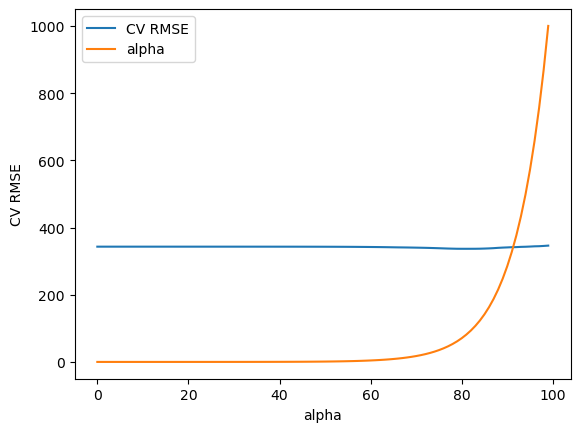

In [83]:
# plot cv values against alpha parameters
import matplotlib.pyplot as plt

alphas = grid.cv_results_['param_alpha'].data.astype(float)
rmse = np.sqrt(-grid.cv_results_['mean_test_score'])


plt.plot(rmse, label='CV RMSE')
plt.plot(alphas, label='alpha')
plt.xlabel('alpha')
plt.ylabel('CV RMSE')
plt.legend()
plt.show()

**Task 6:**
* Ridge regression works best when the input variables are standardised. (See section 6.2 **ISLR** for more details.). Try standardising your data before running your model. Do you find different results?
* does this model outperform a simple linear regression model?
* Which variables are most important in the model?
* Make a pairplot or scatter matrix: pd.plotting.scatter_matrix

**These and other things to consider in this problem...**

* We must actually standardise our *X* variables by scaling each *X* by the standard deviation, if not Ridge will not penalise each variable in the same way. We will learn a robust and easy way to do this in the intro to ML module.
* Once our variables are scaled we can use the $\beta$ coefficients that our model finds to see which has a greater influence in our model. We can find as we see below.
* The reason our model does not perform so well is that most of our *X* variables do not have a very clear linear relationship with *y* (see below)! Using non-linear models could be of use in this problem...again we will cover these soon!

In [86]:
# Your solution here
from sklearn.preprocessing import StandardScaler
#standardize data
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_train_scaled

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
player,,,,,,,,,,,,,,,,
-Ozzie Guillen,1.000434,0.679912,-1.105038,0.147801,-0.189856,-1.405276,-1.110994,-0.698876,-0.686170,-0.794495,-0.692556,-0.769664,-0.888912,-0.141681,2.453172,2.135975
-Milt Thompson,-0.723619,-0.735348,-0.648456,-0.658387,-1.136317,-0.740404,-0.899472,-0.896033,-0.853703,-0.736728,-0.862898,-0.911585,-0.813165,-0.303922,-0.800359,-1.016202
-Glenn Wilson,1.257652,1.159274,0.378855,0.631514,1.269272,0.019449,-0.476428,-0.130651,-0.135270,-0.159053,-0.293133,-0.057041,-0.472302,0.090092,-0.665387,-0.700984
-Mookie Wilson,-0.153569,0.063589,-0.306019,0.268730,-0.268727,-0.455460,-0.053384,0.152170,0.163574,-0.367016,0.253135,-0.259354,-0.343532,-0.250945,-0.757736,-0.543375
-Davey Lopes,-1.029499,-0.849482,-0.534310,-0.214984,-0.663086,0.066939,1.638792,1.571012,1.411775,0.950082,1.921311,0.824678,2.125828,-0.836999,-0.423859,-0.070549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
-Bill Buckner,1.570484,1.387542,0.721291,0.752443,1.979118,-0.075533,2.273358,2.480602,2.623754,1.065617,1.889004,2.225767,0.542711,2.527016,0.307830,0.875104
-Pete Rose,-1.154632,-1.260364,-1.333329,-1.585504,-1.057445,-0.550441,3.542490,4.903739,5.328442,1.019403,5.287031,2.956507,4.951200,0.725811,-0.502000,-0.385766
-Danny Tartabull,0.750168,0.702739,1.520311,0.873371,1.742503,0.921774,-0.899472,-0.890867,-0.847666,-0.505658,-0.815907,-0.679077,-0.710906,-0.486029,-0.757736,-0.070549


In [88]:
# run model and compare with results from non-standardized X
model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='neg_mean_squared_error')

rmse_scores = np.sqrt(-scores)

print("RMSE per fold:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Std RMSE:", rmse_scores.std())

param_grid = {'alpha': np.logspace(-3, 3, 100)}

grid = GridSearchCV(
    estimator=Lasso(max_iter=10000),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best alpha:", grid.best_params_)
print("Best CV RMSE:", np.sqrt(-grid.best_score_))

y_pred = grid.predict(X_test)
from sklearn.metrics import mean_squared_error, r2_score
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R²:", r2_score(y_test, y_pred))

RMSE per fold: [357.95311355 341.1268485  277.03943476 391.82869539 451.31297483]
Mean RMSE: 363.8522134035662
Std RMSE: 57.48002863496059
Best alpha: {'alpha': np.float64(30.538555088334185)}
Best CV RMSE: 337.94354889668614
Test RMSE: 109394.31399808222
Test R²: -66162.44776002922


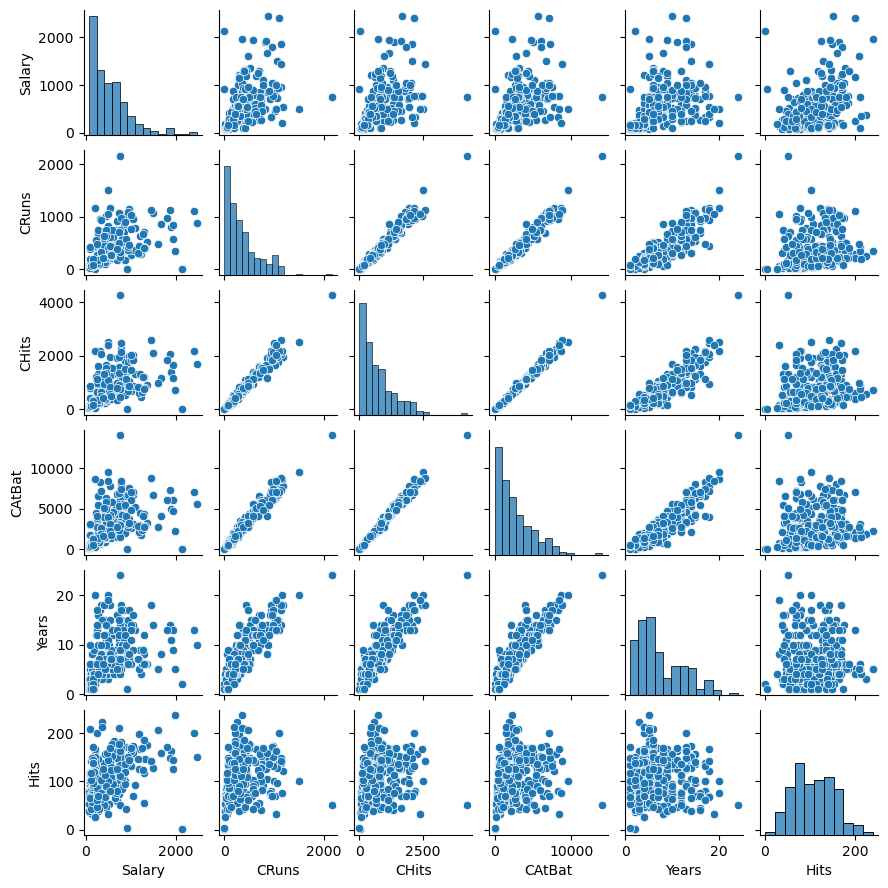

In [92]:
#### solution plot scatter matrix
import seaborn as sns

cols = ['Salary', 'CRuns', 'CHits', 'CAtBat', 'Years', 'Hits']

sns.pairplot(hitters[cols], height=1.5);

## To summarize

* **K-fold cross-validation** splits training data into k subsets, using each as a validation set once. This process estimates model performance and helps select optimal hyperparameters. Finally, the chosen model is evaluated on a separate, held-out test set to assess its generalization ability.

* **cross_val_score** simplifies evaluation by computing metrics (e.g., MSE) across folds, while cross_val_predict generates predictions for each sample.

* **Lasso (L1)** and **Ridge (L2)** regression constrain coefficients to prevent overfitting:
> * Lasso can zero out irrelevant features (feature selection).
> * Ridge shrinks coefficients but rarely to zero, useful when predictors outnumber observations.

* Hyperparameter tuning: **GridSearchCV** automates searching for the optimal regularization strength (alpha) via cross-validation.

* **RandomizedSearchCV** efficiently explores hyperparameters by sampling randomly, unlike exhaustive GridSearchCV.